In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sns


In [2]:
df = pd.read_csv('flights.csv')

In [3]:
df.head()

,flt_id,dof,adep,ades,model,icao_operator,duration_min,delay_min
0,RYR404A,2025-01-11,LPPR,LEBL,Boeing 737 MAX 8-200,RYR,83.333333,-2.333333
1,DLH3AK,2025-01-17,EDDF,EPKK,A320-214,DLH,84.166667,12.333333
2,AFR1405,2025-01-13,LIRF,LFPG,A320 214,AFR,102.250000,-0.750000
3,AFR7464,2025-01-14,LFPG,LFMT,A320 214,AFR,61.750000,-0.083333
4,DLH81P,2025-01-21,LFMN,EDDF,A320 214,DLH,76.000000,0.416667


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 965425 entries, 0 to 965424
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   flt_id         965407 non-null  str    
 1   dof            965425 non-null  str    
 2   adep           965425 non-null  str    
 3   ades           965425 non-null  str    
 4   model          941784 non-null  str    
 5   icao_operator  965425 non-null  str    
 6   duration_min   965425 non-null  float64
 7   delay_min      965425 non-null  float64
dtypes: float64(2), str(6)
memory usage: 97.1 MB


# 1. Подгонка распределения

Для самого популярного маршрута по каждой авиакомпании подгоните распределение длительностей полета:
* ExpNorm https://en.wikipedia.org/wiki/Exponentially_modified_Gaussian_distribution
* Вейбула
* Леви
* Одно на ваш выбор (Логнормальное)

Оцените качество подгонки распределений с помощью критериев:
* Хи-квадрат
* Колмогорова-Смирнова

In [5]:
from scipy.stats import exponnorm, weibull_min, levy, lognorm, kstest, chisquare

distributions = {
    "ExpNorm":   (exponnorm,  {}),
    "Weibull":   (weibull_min, {"floc": 0}),
    "Levy":      (levy,        {"floc": 0}),
    "Lognormal": (lognorm,     {"floc": 0}),
}


def fit_and_test(values, n_bins=8):
    results = {}
    for name, (dist, fit_kwargs) in distributions.items():
        params = dist.fit(values, **fit_kwargs)

        # Хи-квадрат
        probs = np.linspace(0, 1, n_bins + 1)
        edges = dist.ppf(probs, *params)
        edges[0], edges[-1] = -np.inf, np.inf
        observed, _ = np.histogram(values, bins=edges)
        expected = np.full(n_bins, len(values) / n_bins)
        chi2, chi_p = chisquare(observed, expected)

        # Тест Колмогорова-Смирнова
        ks_stat, ks_p = kstest(values, dist.cdf, args=params)

        results[name] = (ks_stat, ks_p, chi2, chi_p)
    return results


for airline, group in df.groupby("icao_operator"):
    (dep, arr) = group.groupby(["adep", "ades"]).size().idxmax()
    durations = group.loc[(group.adep == dep) & (group.ades == arr), "duration_min"].values

    print(f"\n{airline}  {dep}->{arr}  (n={len(durations)})")
    for name, (ks, ks_p, chi2, chi_p) in fit_and_test(durations).items():
        print(f"  {name:10s}  KS={ks:.4f} (p={ks_p:.4f})   chi2={chi2:.3f} (p={chi_p:.4f})")


AFR  LFMN->LFPO  (n=3333)
  ExpNorm     KS=0.0119 (p=0.7233)   chi2=8.036 (p=0.3295)
  Weibull     KS=0.1645 (p=0.0000)   chi2=1221.506 (p=0.0000)
  Levy        KS=0.6194 (p=0.0000)   chi2=22949.765 (p=0.0000)
  Lognormal   KS=0.0422 (p=0.0000)   chi2=63.678 (p=0.0000)

BAW  EGPH->EGLL  (n=3099)
  ExpNorm     KS=0.0230 (p=0.0745)   chi2=24.353 (p=0.0010)
  Weibull     KS=0.1454 (p=0.0000)   chi2=851.077 (p=0.0000)
  Levy        KS=0.5952 (p=0.0000)   chi2=19887.649 (p=0.0000)
  Lognormal   KS=0.0306 (p=0.0059)   chi2=25.293 (p=0.0007)

DLH  EDDF->EDDB  (n=4368)
  ExpNorm     KS=0.0170 (p=0.1577)   chi2=14.766 (p=0.0391)
  Weibull     KS=0.1712 (p=0.0000)   chi2=1661.744 (p=0.0000)
  Levy        KS=0.6032 (p=0.0000)   chi2=29012.630 (p=0.0000)
  Lognormal   KS=0.0501 (p=0.0000)   chi2=85.136 (p=0.0000)

EZY  EGCC->EHAM  (n=1208)
  ExpNorm     KS=0.0258 (p=0.3884)   chi2=12.265 (p=0.0922)
  Weibull     KS=0.2186 (p=0.0000)   chi2=907.523 (p=0.0000)
  Levy        KS=0.5534 (p=0.0000)   c

# 2. Доверительные интервалы
Найдите маршрут по которому летают наибольшее число компаний. Если таких несколько то выберите самый популярный.
В разрезе каждой авиакомпании
* Оцените вероятность задержки более 15 минут
* Постройте доверительные интервалы
* Сравните между собой. Какие выводы можем сделать?

In [6]:
routes = df.groupby(["adep", "ades"]).agg(
    n_airlines=("icao_operator", "nunique"),
    n_flights=("flt_id", "size"),
).reset_index()
best = routes.sort_values(["n_airlines", "n_flights"], ascending=False).iloc[0]
dep, arr = best.adep, best.ades
print(f"Маршрут: {dep}->{arr}")
print(f"Авиакомпаний={best.n_airlines}")
print(f"Рейсов={best.n_flights}")


subset = df[(df.adep == dep) & (df.ades == arr)]


def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return p, center - half, center + half

rows = []
for airline, g in subset.groupby("icao_operator"):
    n = len(g)
    k = int((g.delay_min > 15).sum())
    p, lo, hi = wilson(k, n)
    rows.append((airline, n, k, p, lo, hi))

res = (pd.DataFrame(rows, columns=["airline", "n", "late", "p_late", "ci_lo", "ci_hi"])
         .sort_values("p_late", ascending=False))
print(res.to_string(index=False))

Маршрут: LROP->LOWW
Авиакомпаний=5
Рейсов=58
airline  n  late   p_late    ci_lo    ci_hi
    AFR  1     1 1.000000 0.206543 1.000000
    DLH  1     1 1.000000 0.206543 1.000000
    RYR 52     4 0.076923 0.030319 0.181738
    BAW  1     0 0.000000 0.000000 0.793457
    EZY  3     0 0.000000 0.000000 0.561506


# 3. Проверка гипотез
Для каждой пары авиакомпаний проверьте гипотезы с помощью тестов:
* о равенстве вероятностей задержек более 15 минут, t-критерий Стьюдента и Хи-квадрат
* о равенстве распределений времен задержек, Критерий Манна-Уитни и Колмогорова-Смирнова

  A   B     nA     nB   t_p  chi2_p  mw_p  ks_p
AFR BAW 101584 138348 0.000   0.000 0.000 0.000
AFR DLH 101584 226617 0.000   0.000 0.000 0.000
AFR EZY 101584 184152 0.000   0.000 0.000 0.000
AFR RYR 101584 200249 0.000   0.000 0.000 0.000
AFR THY 101584  66070 0.000   0.000 0.000 0.000
AFR WZZ 101584  48405 0.000   0.000 0.000 0.000
BAW DLH 138348 226617 0.393   0.397 0.000 0.000
BAW EZY 138348 184152 0.000   0.000 0.000 0.000
BAW RYR 138348 200249 0.000   0.000 0.000 0.000
BAW THY 138348  66070 0.000   0.000 0.000 0.000
BAW WZZ 138348  48405 0.000   0.000 0.000 0.000
DLH EZY 226617 184152 0.000   0.000 0.000 0.000
DLH RYR 226617 200249 0.000   0.000 0.000 0.000
DLH THY 226617  66070 0.000   0.000 0.000 0.000
DLH WZZ 226617  48405 0.000   0.000 0.000 0.000
EZY RYR 184152 200249 0.680   0.685 0.000 0.000
EZY THY 184152  66070 0.000   0.000 0.000 0.000
EZY WZZ 184152  48405 0.000   0.000 0.000 0.000
RYR THY 200249  66070 0.000   0.000 0.000 0.000
RYR WZZ 200249  48405 0.000   0.000 0.00

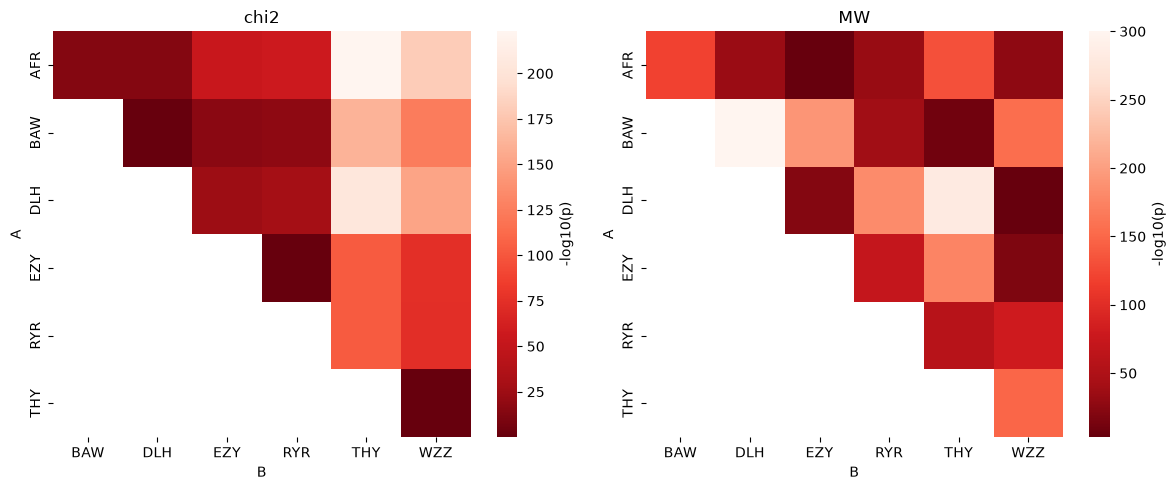

In [7]:
from itertools import combinations
from scipy.stats import ttest_ind, chi2_contingency, mannwhitneyu, ks_2samp

rows = []
for a, b in combinations(sorted(df.icao_operator.unique()), 2):
    da = df[df.icao_operator == a]
    db = df[df.icao_operator == b]

    la = (da.delay_min > 15).astype(int)
    lb = (db.delay_min > 15).astype(int)

    # равенство вероятностей задержки
    t_p = ttest_ind(la, lb, equal_var=False).pvalue
    table = [[la.sum(), len(la) - la.sum()],
             [lb.sum(), len(lb) - lb.sum()]]
    chi2_p = chi2_contingency(table)[1]

    # равенство распределений времени задержек
    mw_p = mannwhitneyu(da.delay_min, db.delay_min).pvalue
    ks_p = ks_2samp(da.delay_min, db.delay_min).pvalue

    rows.append((a, b, len(da), len(db), t_p, chi2_p, mw_p, ks_p))

result = pd.DataFrame(rows, columns=["A", "B", "nA", "nB", "t_p", "chi2_p", "mw_p", "ks_p"])
print(result.to_string(index=False, float_format="%.3f"))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pivot_chi = result.pivot(index="A", columns="B", values="chi2_p").clip(lower=1e-300)
sns.heatmap(-np.log10(pivot_chi), ax=axes[0], cmap="Reds_r",
            cbar_kws={"label": "-log10(p)"})
axes[0].set_title("chi2")

pivot_mw = result.pivot(index="A", columns="B", values="mw_p").clip(lower=1e-300)
sns.heatmap(-np.log10(pivot_mw), ax=axes[1], cmap="Reds_r",
            cbar_kws={"label": "-log10(p)"})
axes[1].set_title("MW")

plt.tight_layout()
plt.show()

# 4. Корреляции
Для каждого маршрута рассчитайте эталонное время полета: duration_min - delay_min. Уберите маршруты по которым было менее 50 полетов.
Разбейте маршруты по категориям:
* Короткие, длительностью менее 1 часа
* Средние, 1-2 часа
* Длинные, более 2 часов

По каждой авиакомпании в разрезе категорий длительности маршрутов оцените корреляции между длительностью полета и задержкой
* Корреляцию Пирсона + доверительный интервал
* Корреляцию Спирмена

airline category      n  pearson_r  pearson_lo  pearson_hi  pearson_p  spearman_r  spearman_p
    AFR     long  10041   0.468205    0.452791    0.483338        0.0    0.460891         0.0
    BAW     long  26565   0.259234    0.247982    0.270417        0.0    0.412524         0.0
    DLH     long  26656   0.415193    0.405208    0.425079        0.0    0.420100         0.0
    EZY     long  45193   0.352308    0.344206    0.360357        0.0    0.480255         0.0
    RYR     long  81606   0.381541    0.375663    0.387388        0.0    0.385801         0.0
    THY     long  49414   0.370089    0.362455    0.377674        0.0    0.320581         0.0
    WZZ     long  25551   0.252902    0.241389    0.264344        0.0    0.255847         0.0
    AFR   medium  70390   0.587554    0.582696    0.592370        0.0    0.520830         0.0
    BAW   medium  81065   0.452785    0.447295    0.458240        0.0    0.347613         0.0
    DLH   medium 105673   0.458214    0.453437    0.462964  

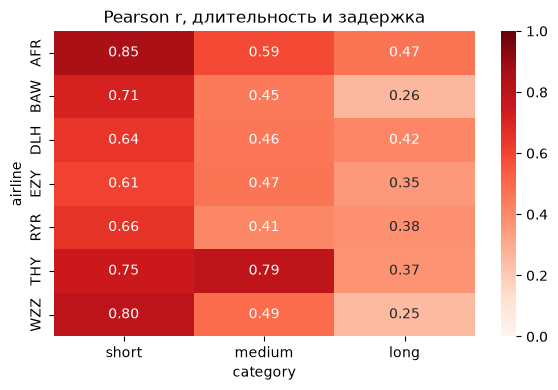

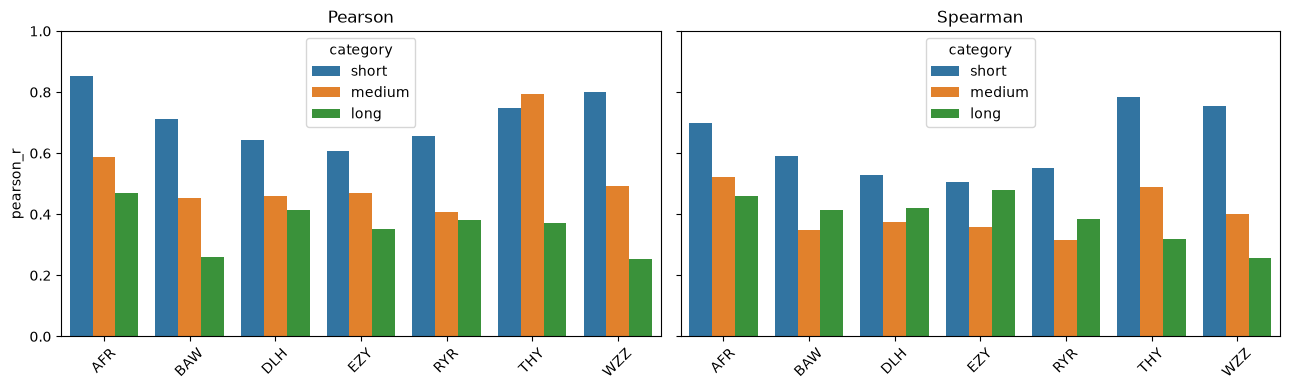

In [8]:
from scipy.stats import pearsonr, spearmanr

df["ref_duration"] = df.duration_min - df.delay_min

routes = (df.groupby(["adep", "ades"])
            .agg(n_flights=("flt_id", "size"),
                 ref_duration=("ref_duration", "median"))
            .query("n_flights >= 50")
            .reset_index())

def route_category(t):
    if t < 60:   return "short"
    if t <= 120: return "medium"
    return "long"

routes["category"] = routes.ref_duration.apply(route_category)

df = df.merge(routes[["adep", "ades", "category"]], on=["adep", "ades"], how="inner")


def pearson_ci(r, n, z=1.96):
    if n <= 3:
        return np.nan, np.nan
    z_r = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    return np.tanh(z_r - z * se), np.tanh(z_r + z * se)


rows = []
for (airline, cat), g in df.groupby(["icao_operator", "category"]):
    if len(g) < 5:
        continue
    n = len(g)
    r_p, p_p = pearsonr(g.duration_min, g.delay_min)
    lo, hi = pearson_ci(r_p, n)
    r_s, p_s = spearmanr(g.duration_min, g.delay_min)
    rows.append((airline, cat, n, r_p, lo, hi, p_p, r_s, p_s))

result = (pd.DataFrame(rows,
                       columns=["airline", "category", "n",
                                "pearson_r", "pearson_lo", "pearson_hi", "pearson_p",
                                "spearman_r", "spearman_p"])
            .sort_values(["category", "airline"]))
print(result.round(6).to_string(index=False))


# Визуализации
cat_order = ["short", "medium", "long"]

pivot = result.pivot(index="airline", columns="category", values="pearson_r")[cat_order]
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Pearson r, длительность и задержка")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col, title in [(axes[0], "pearson_r", "Pearson"),
                       (axes[1], "spearman_r", "Spearman")]:
    sns.barplot(data=result, x="airline", y=col, hue="category",
                hue_order=cat_order, ax=ax)
    ax.set_title(title); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45); ax.set_ylim(0, 1)
axes[0].legend(title="category")
plt.tight_layout(); plt.show()

# 5. Вопросы и гипотезы
Используя подходящие инструменты статистики, ответьте на вопросы
* Задержки в выходные дни происходят чаще
* В разрезе месяцев, количество перелетов и **число** перелетов с задержкой сильно связаны
* В разрезе месяцев, количество перелетов и **частота** перелетов с задержкой сильно связаны

Выходные и будни
weekend: 0.049 (n=268604)
weekday: 0.051 (n=679231)
chi2 p = 0.000309

Объём и число задержек
r = 0.127, p = 0.693099

Объём и доля задержек
r = -0.123, p = 0.704060

 month  n_flights  n_late  late_rate
     1      65133    4255      0.065
     2      73048    3015      0.041
     3      80059    4118      0.051
     4      81074    5683      0.070
     5      83688    7697      0.092
     6      87433    4408      0.050
     7      87086    3254      0.037
     8      81082    1752      0.022
     9      82222    2894      0.035
    10      79192    3126      0.039
    11      69968    3800      0.054
    12      77850    3896      0.050


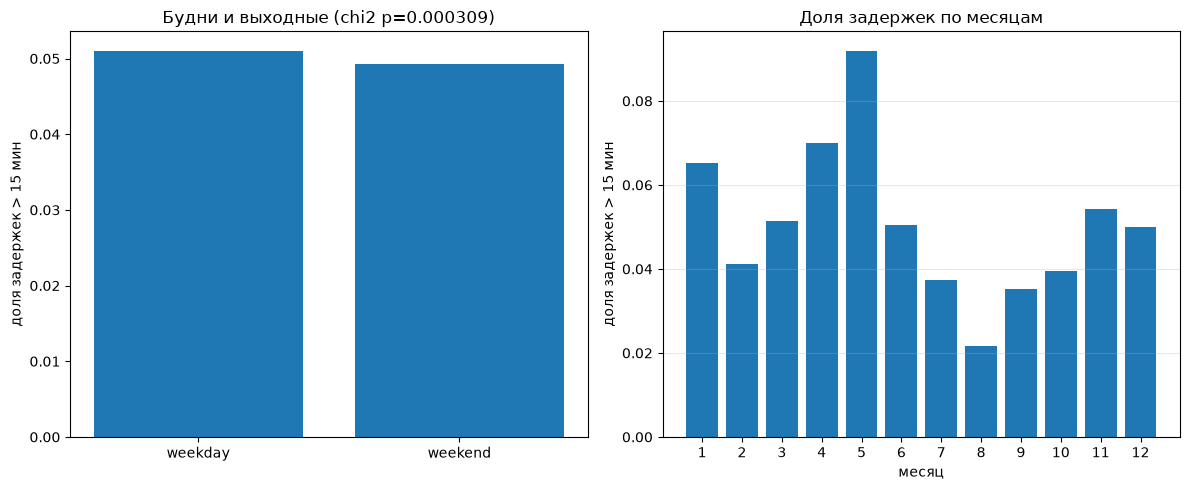

In [9]:
df["dof"] = pd.to_datetime(df["dof"])
df["late"] = (df.delay_min > 15).astype(int)
df["month"] = df.dof.dt.month
df["weekend"] = df.dof.dt.dayofweek >= 5

# Задержки в выходные дни происходят чаще
we = df.loc[df.weekend, "late"]
wd = df.loc[~df.weekend, "late"]

table = [[we.sum(), len(we) - we.sum()],
         [wd.sum(), len(wd) - wd.sum()]]
chi2_p = chi2_contingency(table, correction=False)[1]

print("Выходные и будни")
print(f"weekend: {we.mean():.3f} (n={len(we)})")
print(f"weekday: {wd.mean():.3f} (n={len(wd)})")
print(f"chi2 p = {chi2_p:.6f}\n")

# В разрезе месяцев, количество перелетов и **число** перелетов с задержкой сильно связаны
# В разрезе месяцев, количество перелетов и **частота** перелетов с задержкой сильно связаны
monthly = (df.groupby("month")
             .agg(n_flights=("flt_id", "size"),
                  n_late=("late", "sum"))
             .reset_index())
monthly["late_rate"] = monthly.n_late / monthly.n_flights

r_cnt,  p_cnt  = pearsonr(monthly.n_flights, monthly.n_late)
r_rate, p_rate = pearsonr(monthly.n_flights, monthly.late_rate)

print("Объём и число задержек")
print(f"r = {r_cnt:.3f}, p = {p_cnt:.6f}")
print("\nОбъём и доля задержек")
print(f"r = {r_rate:.3f}, p = {p_rate:.6f}\n")
print(monthly.round(3).to_string(index=False))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(["weekday", "weekend"], [wd.mean(), we.mean()])
axes[0].set_ylabel("доля задержек > 15 мин")
axes[0].set_title(f"Будни и выходные (chi2 p={chi2_p:.6f})")

axes[1].bar(monthly.month, monthly.late_rate)
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("месяц")
axes[1].set_ylabel("доля задержек > 15 мин")
axes[1].set_title("Доля задержек по месяцам")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout(); plt.show()